# Fake News Detection using Machine Learning

## Objective
Develop a machine learning model capable of classifying news articles as **Fake** or **Real** using Natural Language Processing (NLP) techniques and compare the performance of multiple classification algorithms.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import string
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

## 2. Load Dataset
- Describe how the fake and real news datasets were loaded.
- Mention the file paths and the method used to combine them.

In [2]:
fake_df = pd.read_csv('../Data/Fake.csv')
true_df = pd.read_csv('../Data/True.csv')

print(f"Fake news shape :{fake_df.shape}")
print(f"True news shape :{true_df.shape}")


Fake news shape :(23481, 4)
True news shape :(21417, 4)


## 3. Data Understanding
- Explain the structure of the dataset.
- Include the number of rows, columns, and class distribution.

In [3]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
true_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [5]:
fake_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 733.9 KB


In [6]:
true_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    21417 non-null  str  
 1   text     21417 non-null  str  
 2   subject  21417 non-null  str  
 3   date     21417 non-null  str  
dtypes: str(4)
memory usage: 669.4 KB


In [7]:
print("Fake Dataset Missing Values")
print(fake_df.isnull().sum())

print("\nTrue Dataset Missing Values")
print(true_df.isnull().sum())

Fake Dataset Missing Values
title      0
text       0
subject    0
date       0
dtype: int64

True Dataset Missing Values
title      0
text       0
subject    0
date       0
dtype: int64


In [8]:
print("Fake duplicates:", fake_df.duplicated().sum())
print("True duplicates:", true_df.duplicated().sum())

Fake duplicates: 3
True duplicates: 206


In [9]:
print(fake_df.columns)
print(true_df.columns)

Index(['title', 'text', 'subject', 'date'], dtype='str')
Index(['title', 'text', 'subject', 'date'], dtype='str')


## 4. Data Cleaning
-  missing values handling, text normalization, and data cleaning steps.

In [10]:
fake_df['class'] = 0 # fake news
true_df['class'] = 1 # real news

In [11]:
# merging both the datasets
df = pd.concat([fake_df, true_df], ignore_index=True)

print("Combined Dataset Shape:", df.shape)

Combined Dataset Shape: (44898, 5)


In [12]:
df["class"].value_counts()

class
0    23481
1    21417
Name: count, dtype: int64

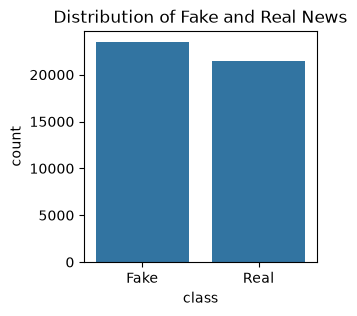

In [13]:
plt.figure(figsize=(3,3))

sns.countplot(data=df,x='class')

plt.title("Distribution of Fake and Real News")
plt.xlabel("class")
plt.ylabel("count")
plt.xticks([0,1],["Fake","Real"])

plt.show()

In [14]:
print("Shape before removing duplicates:", df.shape)

df.drop_duplicates(inplace=True)

print("Shape after removing duplicates:", df.shape)

Shape before removing duplicates: (44898, 5)
Shape after removing duplicates: (44689, 5)


In [15]:
df.reset_index(drop=True, inplace=True)

## 5. Exploratory Data Analysis (EDA)
### Observations
- The combined dataset contains both fake and real news articles.
- The class distribution is nearly balanced, with slightly more fake news articles than real ones.
- No missing values were found in any column.
- The dataset contained duplicate records, which were removed before model training.
- The dataset consists of four text-based features: `title`, `text`, `subject`, and `date`.
- The `text` column contains the main news content and will be used for model training.

### 4.1 Dataset Overview

Before training the models, we analyze the dataset to understand its structure, class distribution, subjects, and text characteristics.

### 4.2 Dataset Shape

In [16]:
print(f"Number of rows : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")

Number of rows : 44689
Number of columns : 5


### 4.3 Subject Distribution


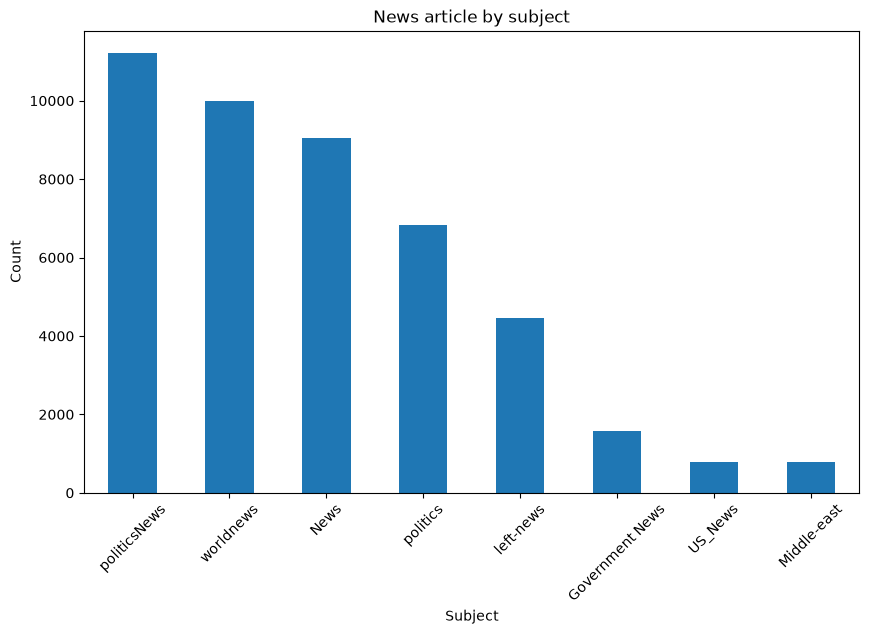

In [17]:
plt.figure(figsize=(10,6))

df["subject"].value_counts().plot(kind="bar")

plt.title("News article by subject")
plt.xlabel("Subject")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()


#### observation
Most articles belong to a few major subjects. This indicates that the dataset covers multiple news domains instead of a single topic.

### 4.4 Fake vs Real Article Length

In [18]:
df["text_length"] = df["text"].str.len()

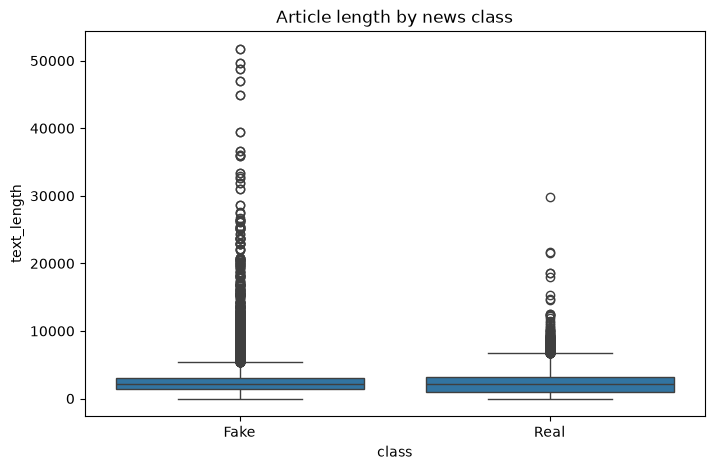

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df,
            x="class",
            y="text_length")

plt.xticks([0,1],["Fake","Real"])

plt.title("Article length by news class")

plt.show()

#### Observation
The boxplot compares article lengths between fake and real news articles and helps identify differences in writing patterns.

### 4.5 word count

In [25]:
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

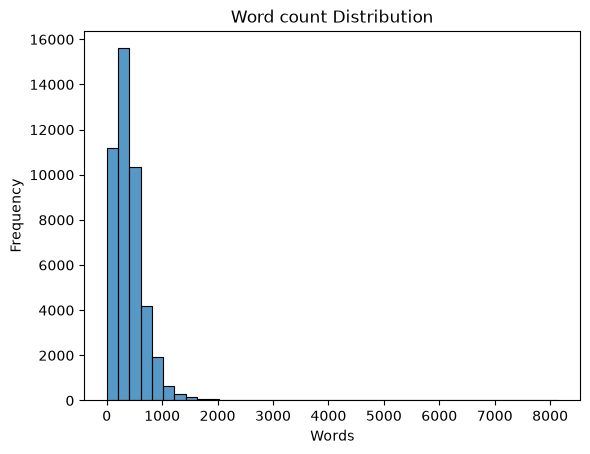

In [26]:
plt.Figure(figsize=(10,5))

sns.histplot(df["word_count"],bins=40)

plt.title("Word count Distribution")

plt.xlabel("Words")
plt.ylabel("Frequency")

plt.show()

## 5. Text Preprocessing
- Describe lowercasing, tokenization, stopword removal, and lemmatization.
- Explain how raw text was converted into cleaner input for modeling.

### 5.1 Create stopwords and lemmatizer

In [21]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

5.2 Define preprocessing function

In [22]:
def preprocess_text(text):

    text = text.lower()

    # remove URL's
    text = re.sub(r'https?://\S+|www\.\S+','',text)

    # remove html tags
    text = re.sub(r'<.*?>','',text)

    # remove punctuation
    text = text.translate(str.maketrans('','',string.punctuation))

    # remove numbers
    text = re.sub(r'\d+','',text)

    # remove extra space
    text = re.sub(r'\s+',' ',text).strip()

    # tokenize
    words = text.split()

    # remove stopwords and lemmatize

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

5.3 applied preprocessing


Why to create a new column?

Instead of overwriting text, we keep both:

text → Original dataset
clean_text → Processed text used for ML

This is a good practice because we can always compare or debug later.

In [23]:
df['clean_text']= df["text"].apply(preprocess_text)


5.4 compare before and after 

In [24]:
for i in range(3):
    print("="*100)
    print("Original:\n")
    print(df.loc[i,"text"][0:500])

    print("\n cleaned \n")
    print(df.loc[i,"clean_text"][0:500])
    print()

Original:

Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do it. As our Country rapidly grows stronger and smarter, I want to wish all of my friends, supporters, enemies, haters, and even the very dishonest Fake News Media, a Happy and Healthy New Year,  President Angry Pants tweeted.  2018 will be a gr

 cleaned 

donald trump wish american happy new year leave instead give shout enemy hater dishonest fake news medium former reality show star one job country rapidly grows stronger smarter want wish friend supporter enemy hater even dishonest fake news medium happy healthy new year president angry pant tweeted great year america country rapidly grows stronger smarter want wish friend supporter enemy hater even dishonest fake news medium happy healthy new year great year america dona

## Step 6: Word Clouds & Most Frequent Words
6.1 Create Fake and Real datasets

In [27]:
fake_text = " ".join(df[df["class"]==0]["clean_text"])
real_text = " ".join(df[df["class"]==1]["clean_text"])

### 6.2 Fake News Word Cloud

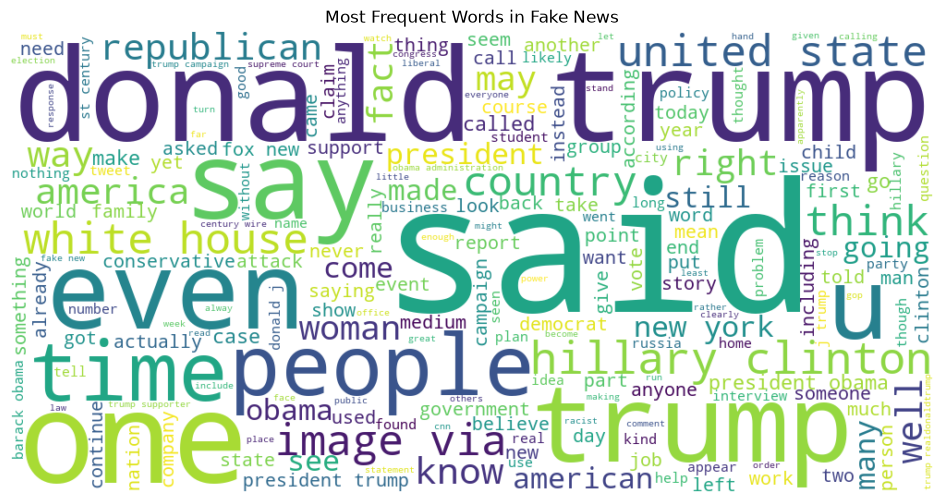

In [28]:
from wordcloud import WordCloud

wordcloud_fake = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(fake_text)

plt.figure(figsize=(14,6))
plt.imshow(wordcloud_fake, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Fake News")
plt.show()

### 6.3 Real News Word Cloud

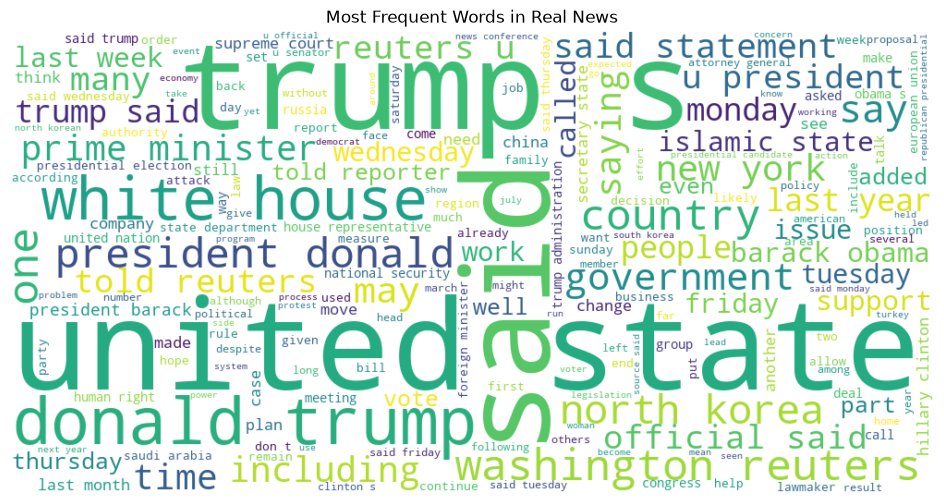

In [29]:
wordcloud_real = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(real_text)

plt.figure(figsize=(14,6))
plt.imshow(wordcloud_real, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Real News")
plt.show()

### 6.4 Top 20 Most Frequent Words

In [30]:
from collections import Counter

In [34]:
def plot_top_words(text, title):

    words = text.split()

    common_words = Counter(words).most_common(15)

    words = [word for word, count in common_words]
    counts = [count for word, count in common_words]

    plt.figure(figsize=(12,6))

    sns.barplot(x=counts, y=words)

    plt.title(title)
    plt.xlabel("Frequency")
    plt.ylabel("Words")

    plt.show()

### Fake news

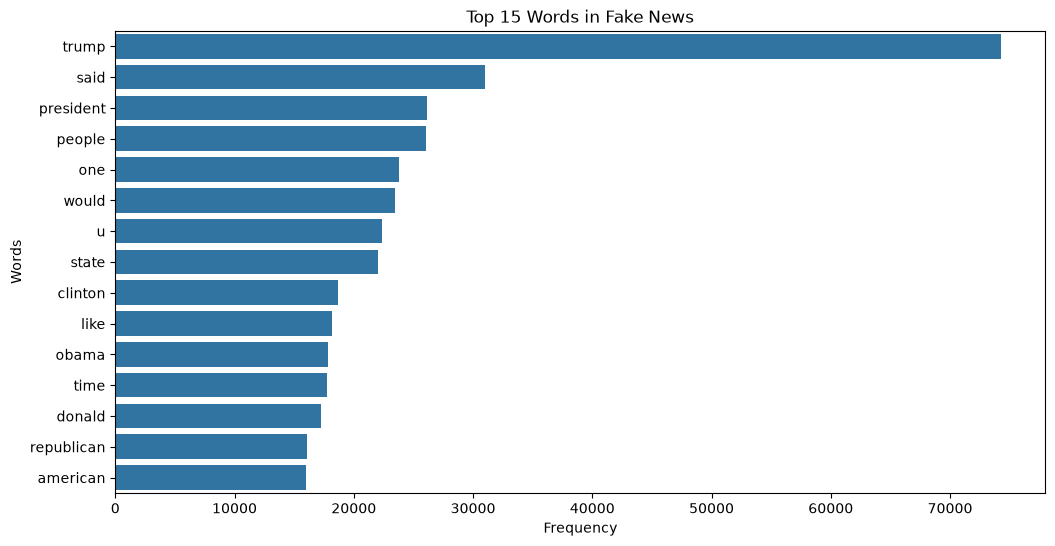

In [35]:
plot_top_words(fake_text, "Top 15 Words in Fake News")

### Real news

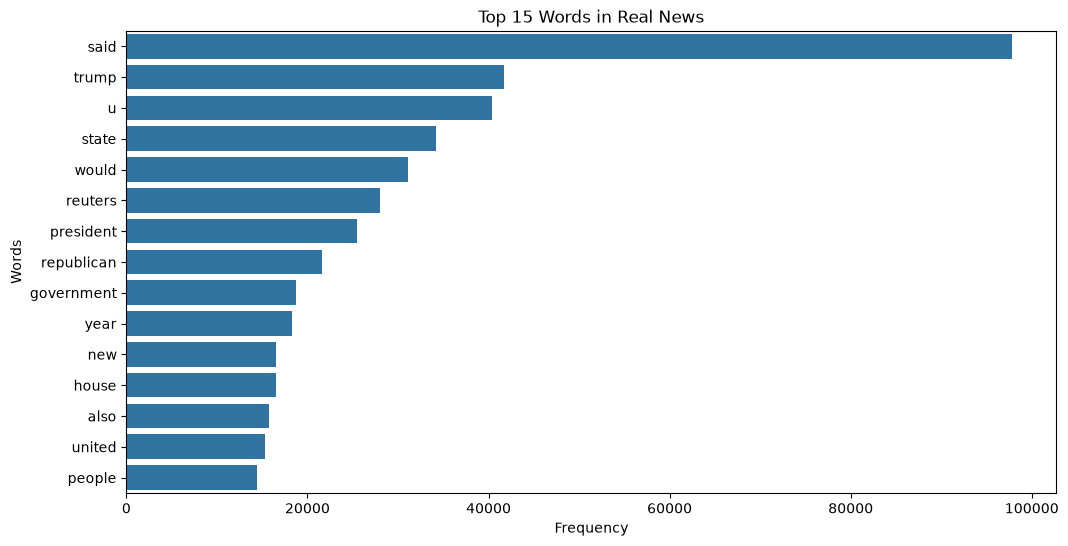

In [36]:
plot_top_words(real_text, "Top 15 Words in Real News")

### Observations

- The word clouds highlight the most frequently occurring words in fake and real news articles.
- Common reporting words appear in both classes, while topic-specific words differ depending on the news category.
- The frequency plots provide a clearer quantitative view of the most common terms than the word clouds alone.

## 7. Feature Engineering (TF-IDF)


7.1 Define Features and Target

In [37]:
X = df["clean_text"]
y = df["class"]

7.2 Train-Test Split
- We'll use stratified sampling to preserve the class distribution.

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

7.3 TF-IDF Vectorization

In [39]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.7,
    min_df=5,
    max_features=50000,
    ngram_range=(1,2)
)

Why these parameters?
- stop_words="english" → removes common English words again at the vectorization stage (harmless even though you've already removed most stopwords).
- max_df=0.7 → ignores terms appearing in more than 70% of documents.
- min_df=5 → ignores extremely rare words that may act as noise.
- max_features=50000 → limits vocabulary size while keeping enough information.
- ngram_range=(1,2) → includes both single words (unigrams) and two-word phrases (bigrams), which often improve fake news classification (e.g., "white house", "north korea").

7.4 Transform the data

In [40]:
X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

In [41]:
print("Training shape :", X_train_tfidf.shape)
print("Testing shape  :", X_test_tfidf.shape)

Training shape : (33516, 50000)
Testing shape  : (11173, 50000)


## 8. Model Training


8.1 Create an evaluation function
This function will:

- Predict on the test set.
- Print accuracy.
- Print the classification report.
- Display the confusion matrix.
- Return the accuracy.

In [46]:
results = []

def evaluate_model(model, X_test, y_test):

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True
    )

    results.append({
        "Model": type(model).__name__,
        "Accuracy": accuracy,
        "Precision": report["weighted avg"]["precision"],
        "Recall": report["weighted avg"]["recall"],
        "F1-Score": report["weighted avg"]["f1-score"]
    })

    print(f"Accuracy: {accuracy:.4f}\n")
    print(classification_report(y_test, y_pred))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        cmap="Blues"
    )

    plt.title(type(model).__name__)
    plt.show()

8.2 Train Logistic Regression

In [47]:
lr = LogisticRegression(max_iter=1000, random_state=42)

lr.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

8.3 Evaluate

Accuracy: 0.9851

              precision    recall  f1-score   support

           0       0.99      0.98      0.99      5870
           1       0.98      0.99      0.98      5303

    accuracy                           0.99     11173
   macro avg       0.98      0.99      0.99     11173
weighted avg       0.99      0.99      0.99     11173



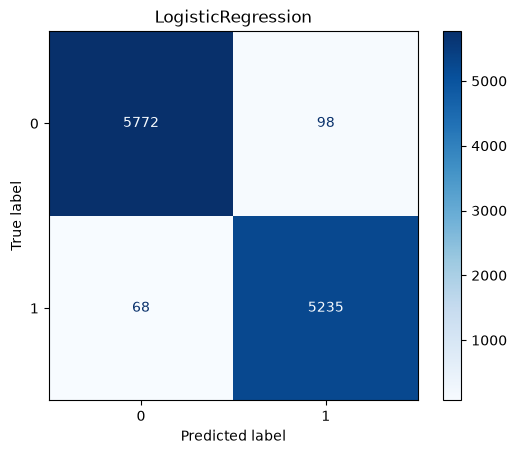

In [48]:
lr_accuracy = evaluate_model(
    lr,
    X_test_tfidf,
    y_test
)

### Step 9: Train the Remaining Models

Decision Tree

Accuracy: 0.9956

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      5870
           1       1.00      0.99      1.00      5303

    accuracy                           1.00     11173
   macro avg       1.00      1.00      1.00     11173
weighted avg       1.00      1.00      1.00     11173



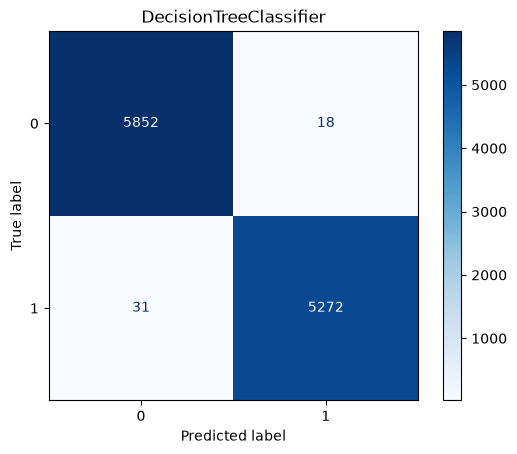

In [50]:
dt = DecisionTreeClassifier(
    random_state=42
)

dt.fit(X_train_tfidf, y_train)

evaluate_model(dt, X_test_tfidf, y_test)

Random Forest

Accuracy: 0.9952

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      5870
           1       0.99      1.00      0.99      5303

    accuracy                           1.00     11173
   macro avg       1.00      1.00      1.00     11173
weighted avg       1.00      1.00      1.00     11173



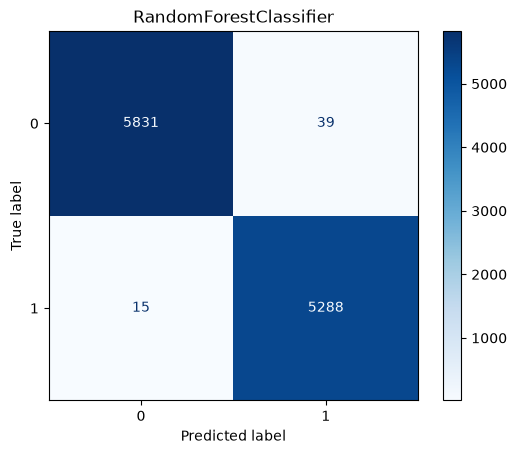

In [51]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_tfidf, y_train)

evaluate_model(rf, X_test_tfidf, y_test)

Multinomial Naive Bayes

In [53]:
from sklearn.naive_bayes import MultinomialNB

Accuracy: 0.9521

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      5870
           1       0.95      0.95      0.95      5303

    accuracy                           0.95     11173
   macro avg       0.95      0.95      0.95     11173
weighted avg       0.95      0.95      0.95     11173



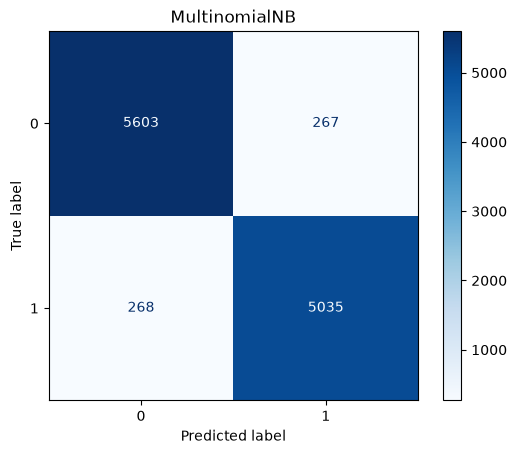

In [54]:
nb = MultinomialNB()

nb.fit(X_train_tfidf, y_train)

evaluate_model(nb, X_test_tfidf, y_test)

Accuracy: 0.9955

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5870
           1       0.99      1.00      1.00      5303

    accuracy                           1.00     11173
   macro avg       1.00      1.00      1.00     11173
weighted avg       1.00      1.00      1.00     11173



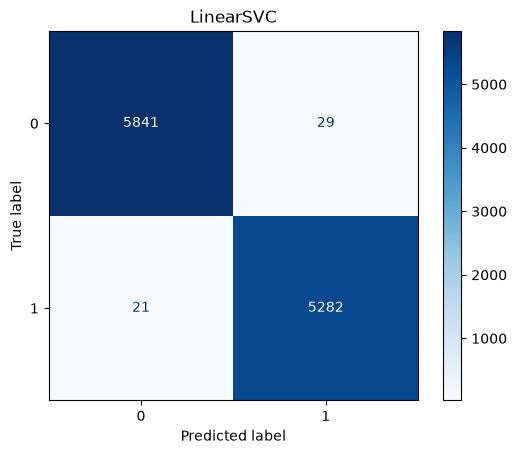

In [55]:
from sklearn.svm import LinearSVC

svm = LinearSVC(random_state=42)

svm.fit(X_train_tfidf, y_train)

evaluate_model(svm, X_test_tfidf, y_test)

## 13. Save the Best Model
- Mention how the best-performing model was saved for future use.
- Include the file format or path used for storage.

In [83]:
joblib.dump(svm, "../models/fake_news_model.pkl")

['../models/fake_news_model.pkl']

In [84]:
joblib.dump(vectorizer, "../models/tfidf_vectorizer.pkl")

['../models/tfidf_vectorizer.pkl']

In [86]:
model = joblib.load("../models/fake_news_model.pkl")
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")

In [87]:
def predict_news(news):

    cleaned = preprocess_text(news)

    vector = vectorizer.transform([cleaned])

    prediction = model.predict(vector)[0]

    if prediction == 0:
        return "Fake News"
    else:
        return "Real News"

In [ ]:
sample = """
The President announced a new economic policy during a press conference held in Washington today.
"""/


print(predict_news(sample))

Fake News


In [88]:
sample = """
The World Health Organization continues to recommend a balanced diet and regular exercise to reduce cardiovascular disease risk"""

print(predict_news(sample))

Fake News


In [89]:
sample = """
Aide tries to refocus U.S. tax debate after Trump's corporate rate remark,"WASHINGTON (Reuters) - President Donald Trump’s weekend remark about a scaled-back tax cut for corporations sparked behind-the-scenes debate in the U.S. Congress, with a White House aide trying on Thursday to minimize the impact of the president’s comment. Two rival tax bills, passed separately by the Senate and the House of Representatives, propose cutting the U.S. corporate tax rate to 20 percent, but they differ in other areas that Republicans are trying to merge into final legislation. Speaking to reporters after the Senate approved its tax bill on Saturday, Trump said the corporate tax rate in the final legislation, expected soon from lawmakers, “could be 22 (percent) ... it could also be 20 (percent).” The remark whetted the interest of some Republicans who see a slight upward bump in the proposed corporate tax rate as  capturing needed federal revenue that would help solve other problems with the legislation, according to lobbyists.  “The 20 percent rate ought to be our goal,” said House Ways and Means Committee Chairman Kevin Brady, who is expected to head a bicameral House-Senate negotiating committee. “My view is the president is giving us flexibility in that area if it’s needed. No decision’s been made on if that’s needed,” the Texas Republican told reporters. But White House legislative affairs director Marc Short told Reuters on Thursday that Trump was not voicing support for a higher proposed corporate rate. Instead, he may have been only expressing views conveyed to him by Republican senators.  “I think he was just reflecting what conversations he had heard from them, but that ... wasn’t intended to signal: this is an endorsement of raising the corporate rate,” Short said. “We believe that 20 percent is the right number ... 20 percent is about as high as we feel comfortable going,” he said in an interview. Trump and his Republican allies have plenty riding on what happens over the next few weeks. A sweeping U.S. tax overhaul, which has not been achieved since 1986, would give Republicans their first major legislative victory of 2017, after their failure to overturn former President Barack Obama’s healthcare law. Without a win, Republicans fear they could lose their control of the House and Senate in the 2018 congressional elections. But it may be too late to avoid confusion over priorities as the tax debate moves forward in Congress. Lobbyists said many perceive that Trump and his advisers would accept a corporate rate higher than 20 percent. White House economic adviser Kevin Hassett said on Thursday that a 22 percent corporate rate would not undermine the economic boost that Republicans say tax cuts will create. Analysts say the corporate income tax rate could be a ready source of revenue for lawmakers, as they move toward a final bill that can lose no more than $1.5 trillion in revenue over the next decade under Senate rules. Republicans are considering a more costly deduction for state and local taxes than the $10,000 property tax deduction contained in the House and Senate bills. One version would allow taxpayers to choose a $10,000 deduction for either property or income taxes. House lawmakers also want to adopt the House bill’s repeal of the corporate alternative minimum tax, which would cost about $40 billion in revenue over a decade, according to the Joint Committee on Taxation. Senate retained the tax. A House limit on the amount of debt interest payments that businesses can deduct from their income would also cost about $136 billion more than the Senate version, the JCT said. Analysts say a one percentage point change in the corporate rate equals about $100 billion in revenues over a decade. ",politicsNews,"December 7, 2017 "
"""
print(predict_news(sample))

Real News
